In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

listings.shape

(4574, 73)

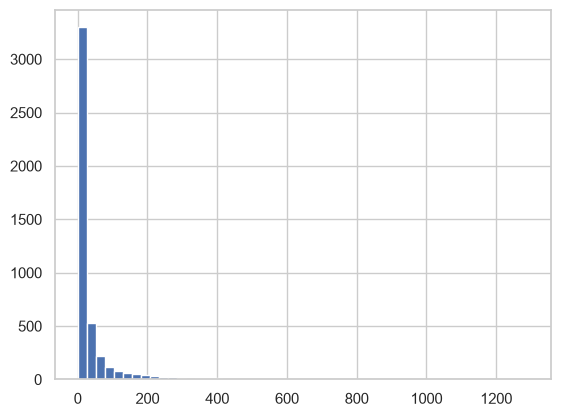

In [9]:
fix, ax = plt.subplots()

ax.hist(listings['number_of_reviews'].dropna(), bins= 50)


plt.show()


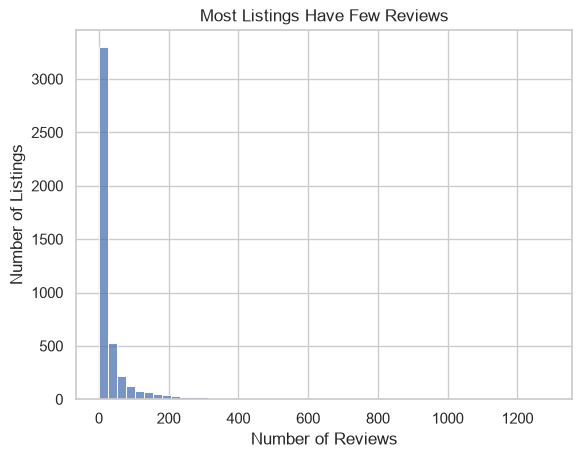

In [10]:
fix, ax = plt.subplots()
sns.histplot(data= listings, x = 'number_of_reviews',  bins=50, ax=ax)

ax.set_title('Most Listings Have Few Reviews')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Number of Listings')
plt.show()

In [24]:
q1 = listings


q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)

upper_fence = q3 + 1.5 * (q3 - q1)

listings['outlier'] = listings['number_of_reviews'] > upper_fence

print(round(upper_fence,1), listings['outlier'].sum())

69.5 582


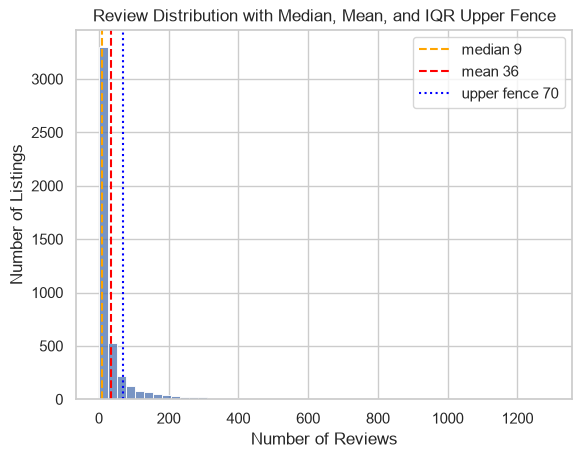

In [38]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

fig, ax = plt.subplots()

sns.histplot(data=listings, x= 'number_of_reviews', bins = 50, ax =ax)

ax.axvline(median, color = 'orange', linestyle= '--', label= f"median {median:,.0f}")
ax.axvline(mean, color = 'red', linestyle= '--', label= f"mean {mean:,.0f}")
ax.axvline(upper_fence, color = 'blue', linestyle= ':', label= f"upper fence {upper_fence:,.0f}")

ax.set_title('Review Distribution with Median, Mean, and IQR Upper Fence')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Number of Listings')
ax.legend()
plt.show()


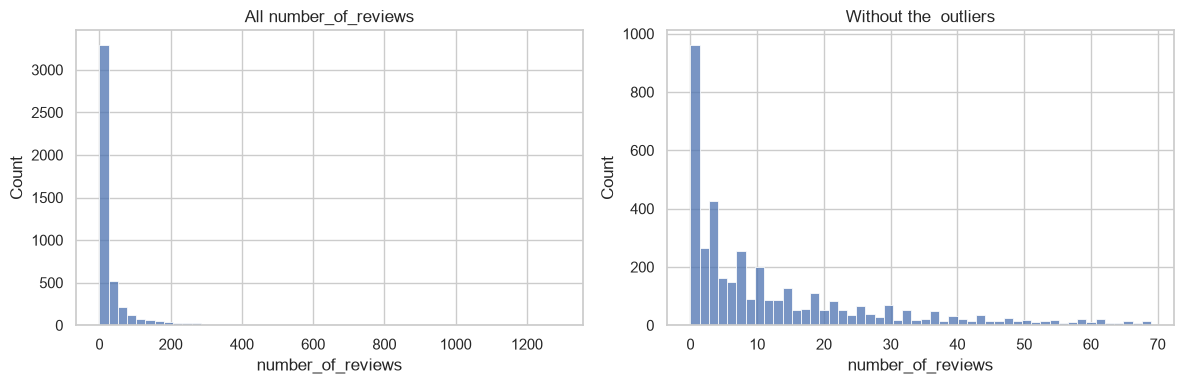

In [41]:
fig, axes = plt.subplots(1,2, figsize=(12,4) )

sns.histplot(data=listings, x= 'number_of_reviews', bins = 50, ax =axes[0])
sns.histplot(data=listings[~listings['outlier']], x= 'number_of_reviews', bins = 50, ax=axes[1])

axes[0].set_title('All number_of_reviews')
axes[1].set_title('Without the  outliers')

for ex in axes:
    ax.set_xlabel('Number of Reviews')
    ax.set_ylabel('Number of Listings')
    
plt.tight_layout()
plt.show()
